In [2]:
#IMPORTS
from sklearn.preprocessing import PowerTransformer
from dython.nominal import associations
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
import pandas as pd
import numpy as np
import math
import re

In [64]:
#CONFIGURACOES
# ---- nao truncar impressao do pandas ---- #
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
# ----------------------------------------- #

In [65]:
df = pd.read_csv("dados/Dados_REG.csv", sep="\t")

# Exploração

In [66]:
#OBTENDO OS TIPOS DE CADA COLUNA E ALGUNS EXEMPLOS DE LINHAS
print(f"Tipos de cada coluna ({len(df.columns)} colunas) -------------------\n", df.dtypes, sep="")
df.head()

Tipos de cada coluna (33 colunas) -------------------
n°                int64
GRAM                str
Cor               int64
Cores               str
Borda           float64
Textura             str
Forma               str
Brilho              str
Muco            float64
Relevo          float64
Atividade 01      int64
Atividade 02    float64
Atividade 03        str
Atividade 04        str
Atividade 05    float64
Atividade 06    float64
Atividade 07    float64
Atividade 08    float64
Atividade 09    float64
Atividade 10    float64
Atividade 11    float64
Atividade 12    float64
Atividade 13      int64
Atividade 14    float64
Atividade 15    float64
Atividade 16        str
Atividade 17      int64
Atividade 18      int64
Atividade 19      int64
Atividade 20    float64
Atividade 21    float64
Atividade 22      int64
Atividade 23        str
dtype: object


,n°,GRAM,Cor,Cores,Borda,Textura,Forma,Brilho,Muco,Relevo,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
0,1413,Negativo,1,2,0.0,1,1,2,0.0,1.0,0,0.00,Negativo,Negativo,1.20,0.00,0.00,-0.01,0.76,0.54,0.74,0.06,1,0.00,0.0,Positivo,1,1,3,1.0,3.0,0,2.767
1,1414,Positivo,1,2,0.0,1,4 & 1,2,0.0,0.0,0,2.33,Negativo,Negativo,1.20,-0.01,0.13,-0.04,0.28,0.10,0.09,0.04,0,2.80,3.0,Positivo,3,3,2,3.0,3.0,0,12.678
2,1415,Positivo,1,2,0.0,2 & 1,4 & 1,2,0.0,0.0,0,3.50,Negativo,Negativo,1.38,0.00,0.43,0.01,0.12,0.26,0.27,0.14,0,2.00,2.5,Positivo,3,3,3,3.0,3.0,3,6.87
3,1417,Negativo,1,2,0.0,1,1,2,0.0,1.0,0,0.00,Negativo,Negativo,1.25,0.67,0.11,0.03,0.99,0.67,0.24,0.11,2,0.00,0.0,Positivo,0,0,0,0.0,1.0,0,2.728
4,1418,Positivo,1,3,0.0,1,4 & 1,2,0.0,0.0,0,1.75,Negativo,Negativo,1.20,0.00,0.10,-0.02,0.24,0.26,0.09,0.17,0,2.33,1.2,Positivo,2,3,0,3.0,3.0,3,11.353


In [67]:
#OBTENDO METRICAS BASICAS DE CADA COLUNA
# mean   -> media arit. dos valores
# median -> mediana (valor central dos dados ordenados)
# std    -> desvio padrao (mede a dispersao dos valores em torno da media)
#           - baixo = valores menos dispersos (mais proximos da media)
#           - alto  = valores mais dispersos (mais afastados da media)
#
# min    -> menor valor encontrado
# max    -> maior valor encontrado
# skew   -> assimetria da distribuicao dos dados (obliquidade)
#           - perto de zero = pouca assimetria (distribuicao aproximadamente simetrica)
#           - positivo      = cauda mais longa a direita
#           - negativo      = cauda mais longa a esquerda

resumo_num = df.select_dtypes(include="number").agg([
    "mean",
    "median",
    "std",
    "min",
    "max",
    "skew"
]).T

resumo_cat = df.select_dtypes(exclude="number").describe().T

print("-- Resumo dos valores numericos ----------------------------------------\n",resumo_num, "\n", sep="")
print("-- Resumo dos valores categoricos --------------------------------------\n",resumo_cat, sep="")

-- Resumo dos valores numericos ----------------------------------------
                     mean    median         std      min      max      skew
n°            1697.019763  1694.500  156.279135  1413.00  1965.00 -0.003626
Cor              1.138340     1.000    0.345598     1.00     2.00  2.101257
Borda            0.344554     0.000    0.693003     0.00     2.00  1.718671
Muco             0.267857     0.000    0.447745     0.00     2.00  1.118107
Relevo           0.387674     0.000    0.487705     0.00     1.00  0.462470
Atividade 01     0.041502     0.000    0.199646     0.00     1.00  4.611348
Atividade 02     0.947648     0.000    1.251782     0.00     5.83  0.960974
Atividade 05     0.706601     1.000    0.682174     0.00     3.60  0.428358
Atividade 06     0.089545     0.010    0.194507    -0.06     0.81  2.138710
Atividade 07     0.122826     0.100    0.127130    -0.08     0.81  2.237261
Atividade 08     0.017292     0.010    0.036184    -0.19     0.16 -0.048863
Atividade 09   

In [68]:
#VENDO SE "Cor" APRESENTA 1 QUANDO TEM 1 COR EM "Cores" E 2 QUANDO TEM 2 CORES
tem_multi = df["Cores"].astype(str).str.contains("&")

# fazendo crosstab p/ ver quantos "Cor = 1" tem junto com "Cores = numero & numero" (True)
# espera-se "True -> 0" e "False -> 0"
print(pd.crosstab(df["Cor"], tem_multi))

Cores  False  True 
Cor                
1        436      0
2          0     70


In [69]:
#CHECANDO SE TEM ID DUPLICADO
duplicados = df[df['n°'].duplicated(keep=False)]
print(duplicados)

       n°      GRAM  Cor Cores  Borda Textura Forma Brilho  Muco  Relevo  \
111  1551  Negativo    1     3    1.0       2     1      2   0.0     1.0   
112  1551  Negativo    1     3    1.0       2     1      2   0.0     1.0   

     Atividade 01  Atividade 02 Atividade 03 Atividade 04  Atividade 05  \
111             0           0.0     Negativo     Negativo          1.67   
112             0           0.0     Negativo     Negativo          1.00   

     Atividade 06  Atividade 07  Atividade 08  Atividade 09  Atividade 10  \
111          0.00          0.12          0.06          0.35          0.35   
112          0.54          0.10          0.04          0.77          0.54   

     Atividade 11  Atividade 12  Atividade 13  Atividade 14  Atividade 15  \
111          0.23          0.18             1           4.0           0.0   
112          0.19          0.10             0           0.0           0.0   

    Atividade 16  Atividade 17  Atividade 18  Atividade 19  Atividade 20  \
111  

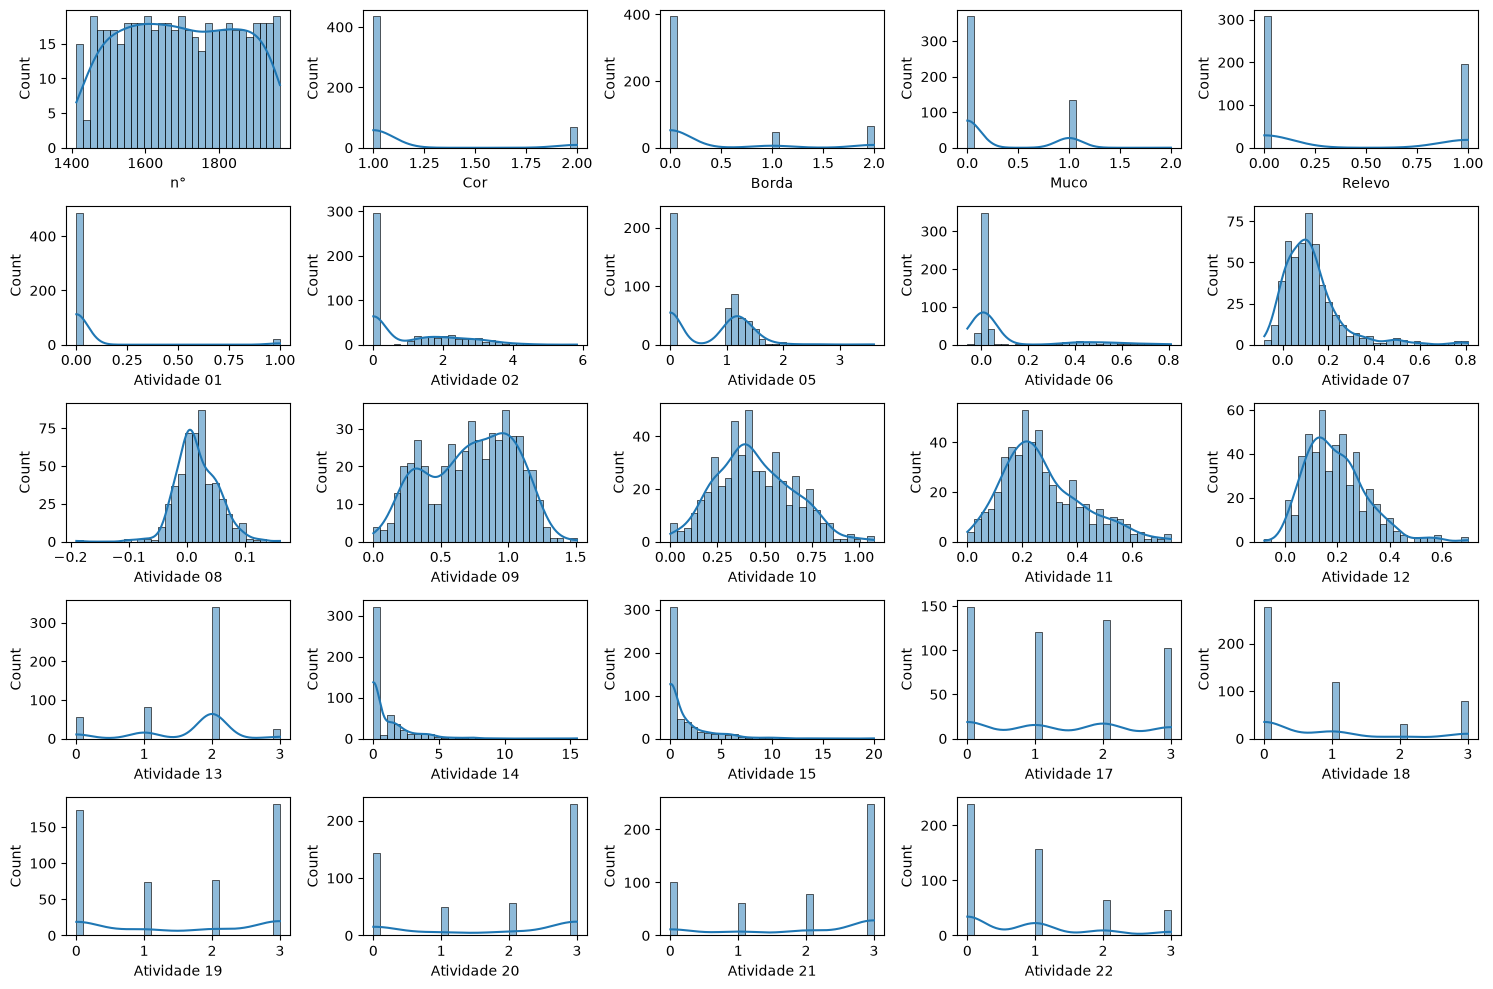

In [70]:
#VISUALIZANDO HISTOGRAMA DAS COLUNAS NUMERICAS JUNTO COM LINHA DE TENDENCIA
numeric_cols = df.select_dtypes(include="number").columns

ncols = 5
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(15, 2 * nrows)
)

axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        edgecolor="black",
        ax=ax
    )

# Remove os subplots vazios
for ax in axes[len(numeric_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

In [71]:
#CHECANDO POR VALORES MUITO PREDOMINANTES NO DATASET
def analisar_valores_predominantes(coluna):
    resultados = []

    for coluna in df.columns:
        contagem = df[coluna].value_counts(dropna=False)

        valor_predominante = contagem.index[0]
        qtd_predominante = contagem.iloc[0]

        total = len(df)
        qtd_restante = total - qtd_predominante

        percentual_predominante = (qtd_predominante / total) * 100
        percentual_restante = (qtd_restante / total) * 100

        resultados.append({
            'Coluna': coluna,
            'Valor predominante': valor_predominante,
            'Quantidade predominante': qtd_predominante,
            'Porcentagem predominante (%)': round(percentual_predominante, 2),
            'Quantidade restante': qtd_restante,
            'Porcentagem restante (%)': round(percentual_restante, 2)
        })

    return pd.DataFrame(resultados).sort_values(
        by='Porcentagem predominante (%)',
        ascending=False
    )

resultados = analisar_valores_predominantes(df)
display(resultados)

,Coluna,Valor predominante,Quantidade predominante,Porcentagem predominante (%),Quantidade restante,Porcentagem restante (%)
13,Atividade 04,Negativo,487,96.25,19,3.75
10,Atividade 01,0,485,95.85,21,4.15
12,Atividade 03,Negativo,478,94.47,28,5.53
2,Cor,1,436,86.17,70,13.83
4,Borda,0.0,395,78.06,111,21.94
7,Brilho,2,372,73.52,134,26.48
8,Muco,0.0,370,73.12,136,26.88
6,Forma,1,355,70.16,151,29.84
25,Atividade 16,Positivo,349,68.97,157,31.03
22,Atividade 13,2,341,67.39,165,32.61


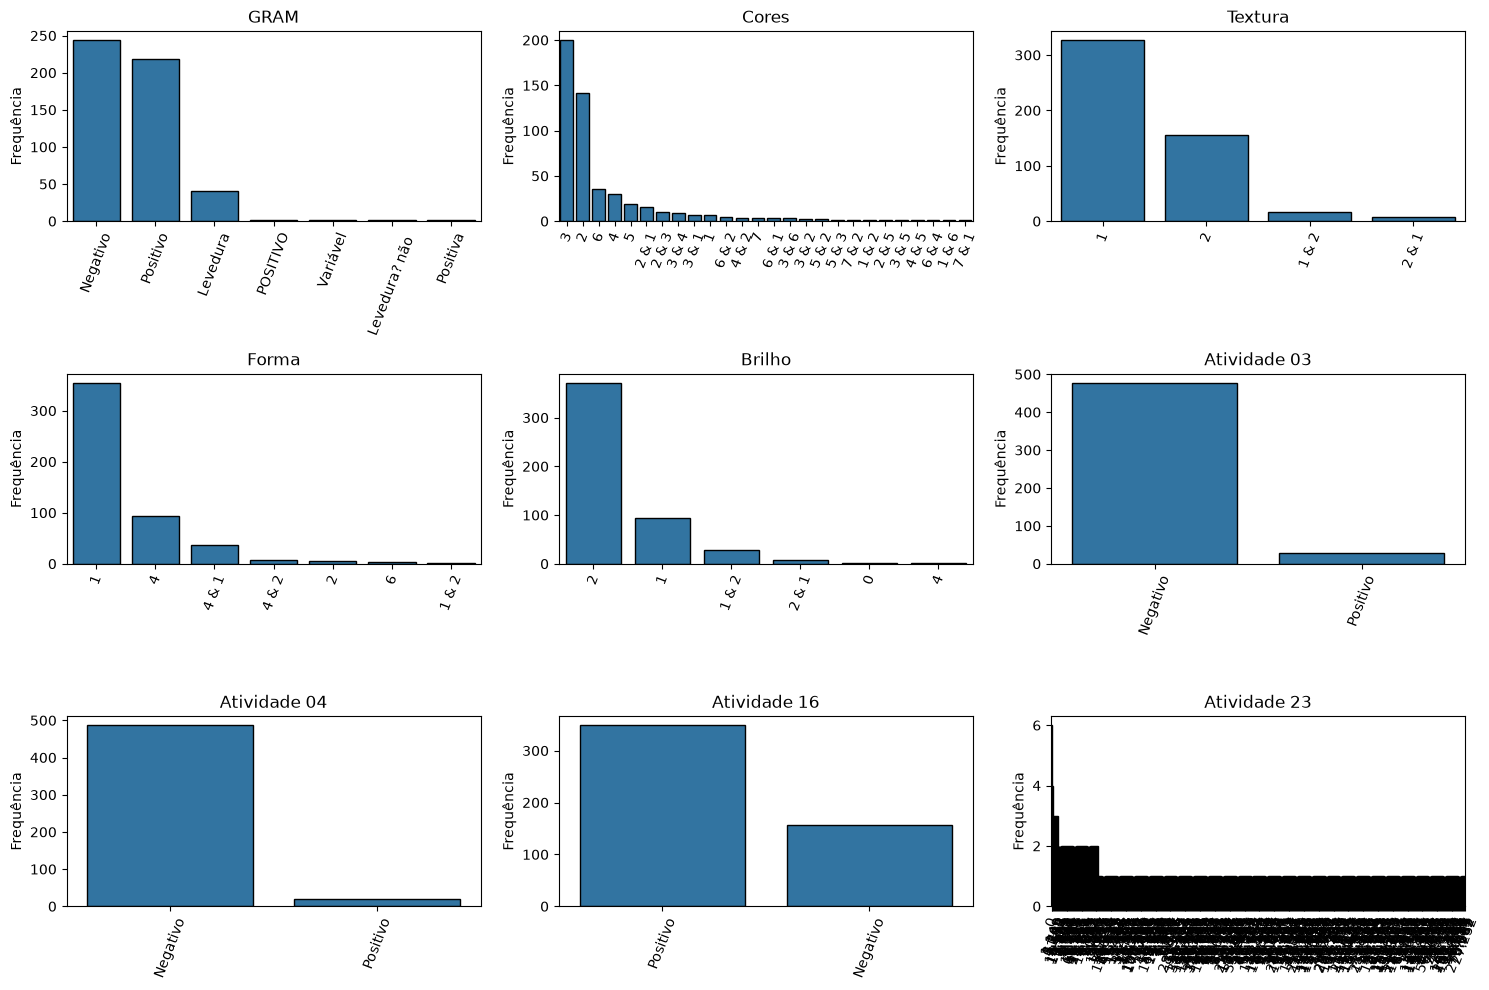

In [72]:
#VISUALIZANDO HISTOGRAMA DAS COLUNAS CATEGORICAS
cat = df.select_dtypes(exclude="number")

fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, col in zip(axes.flat, cat.columns):
    sns.countplot(
        data=df,
        x=col,
        ax=ax,
        edgecolor="black",
        order=df[col].value_counts().index,
    )

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Frequência")
    ax.tick_params(axis="x", rotation=69)

# Remove gráficos vazios
for ax in axes.flat[len(cat.columns):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

In [73]:
#CHECANDO POR QUE ATIVIDADE 23 EH CATEGORICO
s = df["Atividade 23"].astype("string").str.strip()
forma = (s.str.replace(r"\d", "9", regex=True).str.replace(r"[A-Za-z]", "A", regex=True))

print(forma.map(repr).value_counts(dropna=False))

Atividade 23
'99.999'     203
'9.999'      183
'999.999'     59
'99.99'       21
'9.99'        20
'9'            8
'999.99'       4
<NA>           3
'9.9'          2
'999.9'        2
'#AÚA!'        1
Name: count, dtype: int64


In [74]:
#CHECANDO POR VALORES NULOS
print("-- Colunas com valores nulos -------------------------\n", df.isna().sum().sort_values(ascending=False).loc[lambda x: x > 0], sep="")
print("------------------------------------------------------")

qtd_linhas_null = df.isnull().any(axis=1).sum()
qtd_linhas = len(df.index)
print("Quantidade de linhas com 1 ou mais valores nulos = ", qtd_linhas_null, " (", f"{(qtd_linhas_null/qtd_linhas)*100:.2f}","% do dataset)" ,sep="")

# contando qtd de linhas com n valores nulos
#qtd_nulos = df.isnull().sum(axis=1).value_counts().sort_index()
#print(qtd_nulos)

qtd = df.isnull().sum(axis=1).eq(1).sum()
print(f"+-> Linhas com exatamente 1 nulo:\t{qtd}")
qtd = df.isnull().sum(axis=1).eq(2).sum()
print(f"+-> Linhas com exatamente 2 nulos:\t{qtd}")
qtd = df.isnull().sum(axis=1).eq(4).sum()
print(f"+-> Linhas com exatamente 4 nulos:\t{qtd}")
qtd = df.isnull().sum(axis=1).eq(6).sum()
print(f"+-> Linhas com exatamente 6 nulos:\t{qtd}")

-- Colunas com valores nulos -------------------------
Atividade 20    27
Atividade 21    17
Relevo           3
Atividade 23     3
Forma            2
Muco             2
Brilho           2
Borda            1
Textura          1
dtype: int64
------------------------------------------------------
Quantidade de linhas com 1 ou mais valores nulos = 38 (7.51% do dataset)
+-> Linhas com exatamente 1 nulo:	24
+-> Linhas com exatamente 2 nulos:	12
+-> Linhas com exatamente 4 nulos:	1
+-> Linhas com exatamente 6 nulos:	1


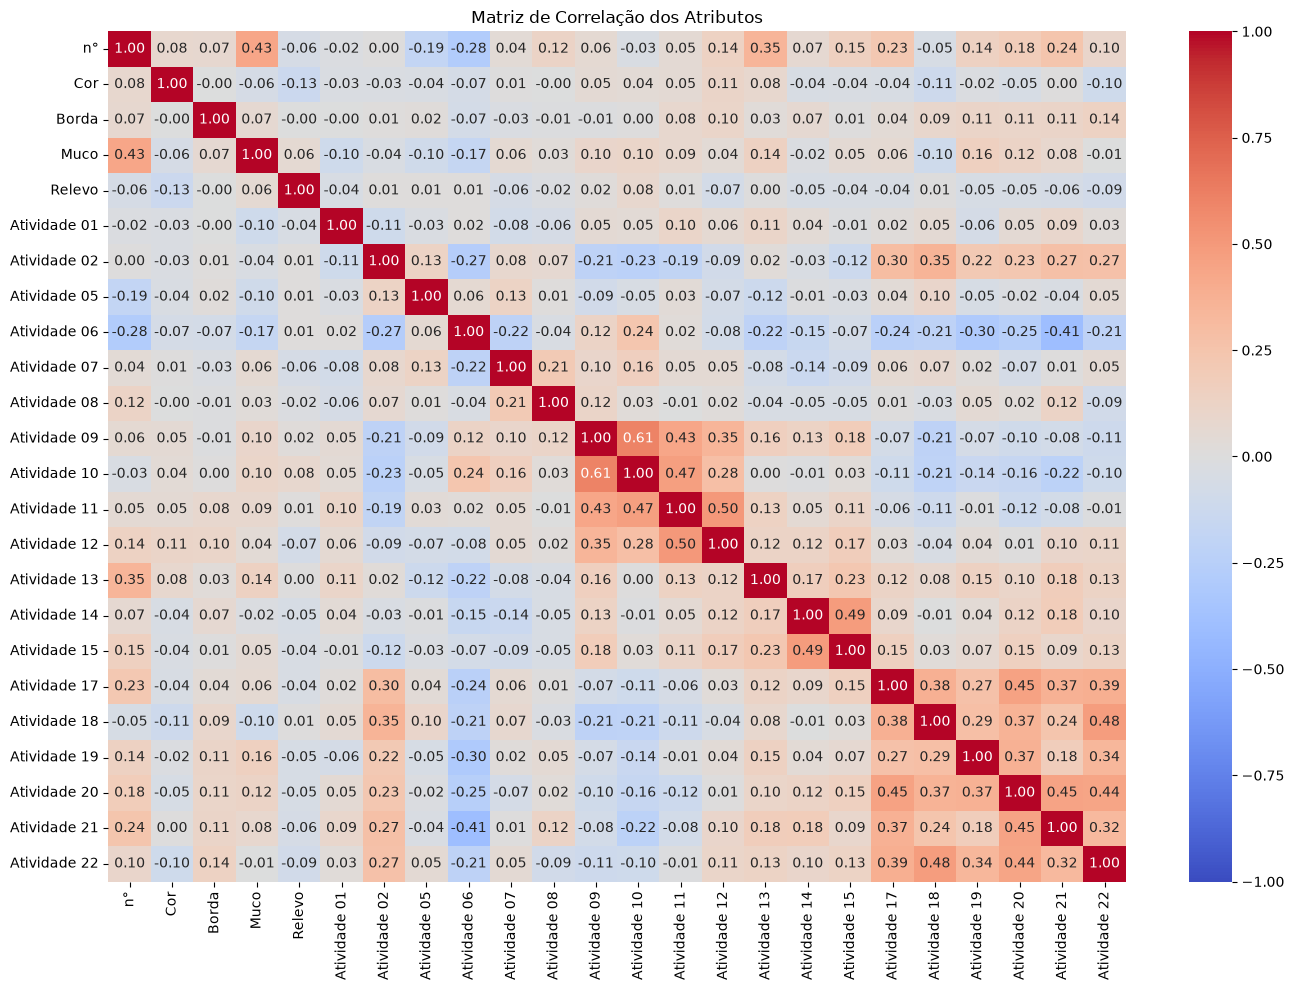

In [75]:
#VISUALIZANDO MATRIZ DE CORRELACAO ENTRE ATRIBUTOS
# valor negativo -> enquanto um desce o outro sobe, e vice-versa
# valor perto de zero -> sem relacao linear
# valor positivo -> os dois sobem junto

# calcula a matriz de correlação entre colunas numéricas
correlacao = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlacao,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Matriz de Correlação dos Atributos')
plt.tight_layout()
plt.show()

In [6]:
#MOSTRANDO VALORES OUTLIERS NOS DADOS
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return serie[(serie < limite_inf) | (serie > limite_sup)]

coluna = "Atividade 15"
out = outliers_iqr(df[coluna])
print(f"{len(out)} outliers encontrados")
print(df.loc[out.index][coluna])

55 outliers encontrados
45      4.67
69     20.00
151     5.00
161     7.50
167     6.17
168     5.67
176     5.63
196     4.33
197     5.00
203     4.33
216     4.60
232     6.67
233     5.00
236    13.50
238     6.00
241     5.33
242     6.50
259     7.50
260     8.33
261    10.00
262     6.67
272     5.60
286     9.50
299    10.67
300     5.17
303     9.33
308     6.00
314     6.00
318     6.00
327     4.29
334    10.00
337     8.50
340     5.00
349     5.00
350    11.60
351     5.60
358     7.14
363     8.29
384     7.11
386     4.29
390     4.67
392     5.00
398     5.50
401     5.67
414     6.00
416     6.00
439     5.67
442     6.40
443     4.75
445     5.71
453     6.00
455     6.33
467    10.00
479     5.20
497     5.00
Name: Atividade 15, dtype: float64


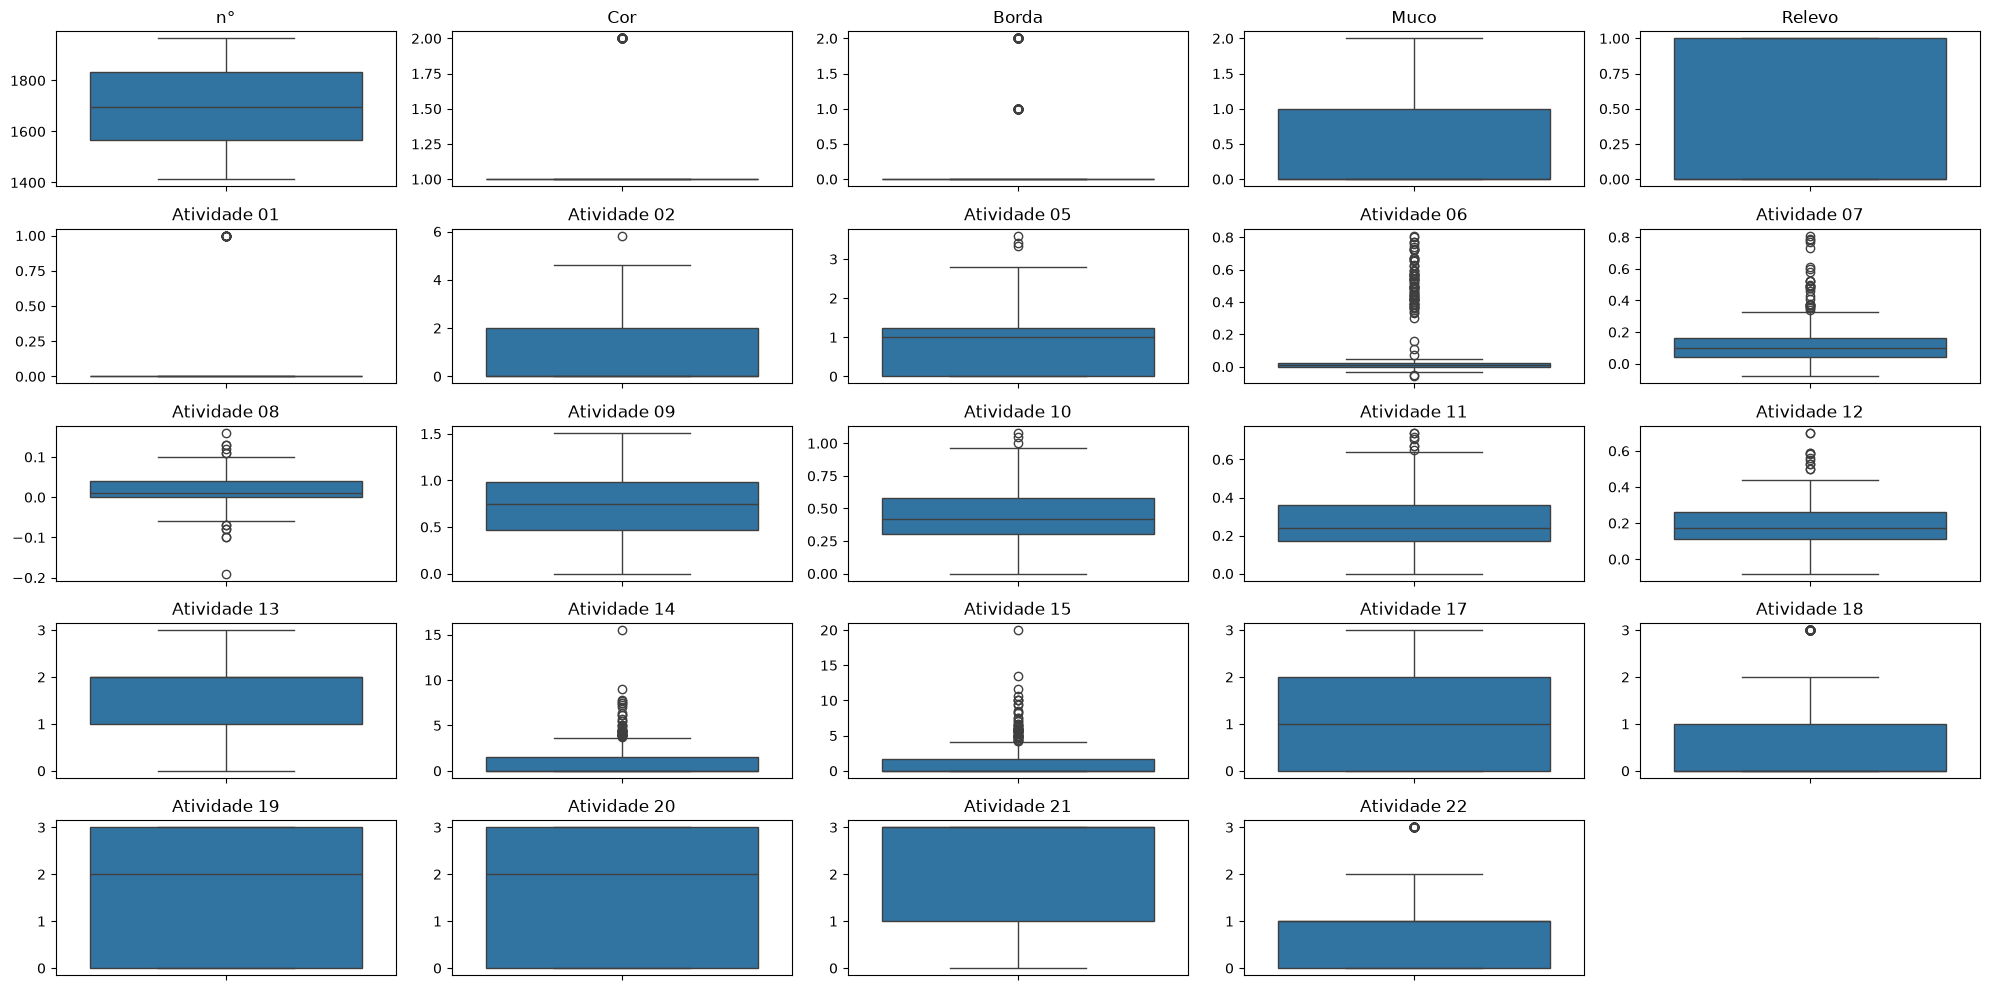

In [77]:
#VISUALIZANDO BOXPLOT DOS VALORES NUMERICOS
cols = df.select_dtypes("number").columns[:50]  

fig, axes = plt.subplots(5, 5, figsize=(20, 10))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# Conclusões da exploração

| Coluna | Conclusão/Problema identificado | Solução proposta | Justificativa | Status |
|---|---|---|---|---|
| **n°** | Possui 1 valor duplicado (1551), em que ambas as linhas apresentam valores iguais para Morfologia e Atividades 01, 02, 03 e 04. | Remover uma das duas linhas duplicadas (provavelmente a última). | Evitar problemas de representação e possíveis erros decorrentes da inserção de dados morfológicos na linha duplicada. | Feito |
| **n°** | Coluna utilizada apenas para identificação, sem potencial para revelar padrões de grupo. | Remover a coluna por completo. | Evitar manter uma variável sem relevância para a análise de padrões. | Feito |
| **GRAM** | Apresenta inconsistencias na nomenclatura (POSITIVO, Positivo, positivo) | Padronizar nomenclatura da coluna | Remover ruido dos dados | Feito
| **GRAM** |Possui 2 valores não definidos originalmente ("Variavel" e "Lavedura? não") | Remover linha inteira | Valores não previstos na descrição do trabalho são desconsiderados por ser assumido erro | Feito |
| **Cor** | Apresenta relação esperada de 1 quando "Cores" possui uma cor e 2 quando possui duas cores. | Remover a coluna. | Eliminar redundância entre colunas, reduzir a dimensionalidade e evitar variáveis que não acrescentam informações além das já presentes em "Cores". | Feito |
| **Borda**, **Textura**, **Forma**, **Brilho**, **Muco**, **Relevo**, **Atividade 23** | Possuem entre 1 à 3 valores nulos | Preencher nulos destas colunas com mediana ou moda | Manter as linhas para não perder informação mas não criar tendências novas | Feito
| **Atividade 01**, **Atividade 03**, **Atividade 04** | Possui valores unicos que ocupam 94%-96% da coluna | Remover coluna caso não represente informação importante | Remover informações que possam atrapalhar o treinamento, diminuir dimensionalidade do modelo |
| **Atividade 03**, **Atividade 04**, **Atividade 16** | Possui valores "Positivo" e "Negativo" | Possivel modificação para 1 e 0 dependente de modelo | Alguns modelos só trabalham com valores numéricos |
| **Atividade 20** | Possui 27 valores nulos | Não modificar | Definir o que fazer enquanto treina o modelo |
| **Atividade 21** | Possui 17 valores nulos | Não modificar | Definir o que fazer enquanto treina o modelo |
| **Atividade 23** | Possui 442 valores únicos, indicando que possivelmente deveria ser uma variável numérica, e não categórica. | Transformar a coluna em numérica. | Garantir uma representação mais fiel à natureza dos dados. | Feito |

Outros problemas foram identificados, como possivel distribuição log-normal ou até exponencial, outliers etc., mas o tratamento destes é dependente de modelo

# Visualizando limpeza

In [3]:
df = pd.read_csv("dados/Dados_REG_limpo_baseline.csv", sep="\t")

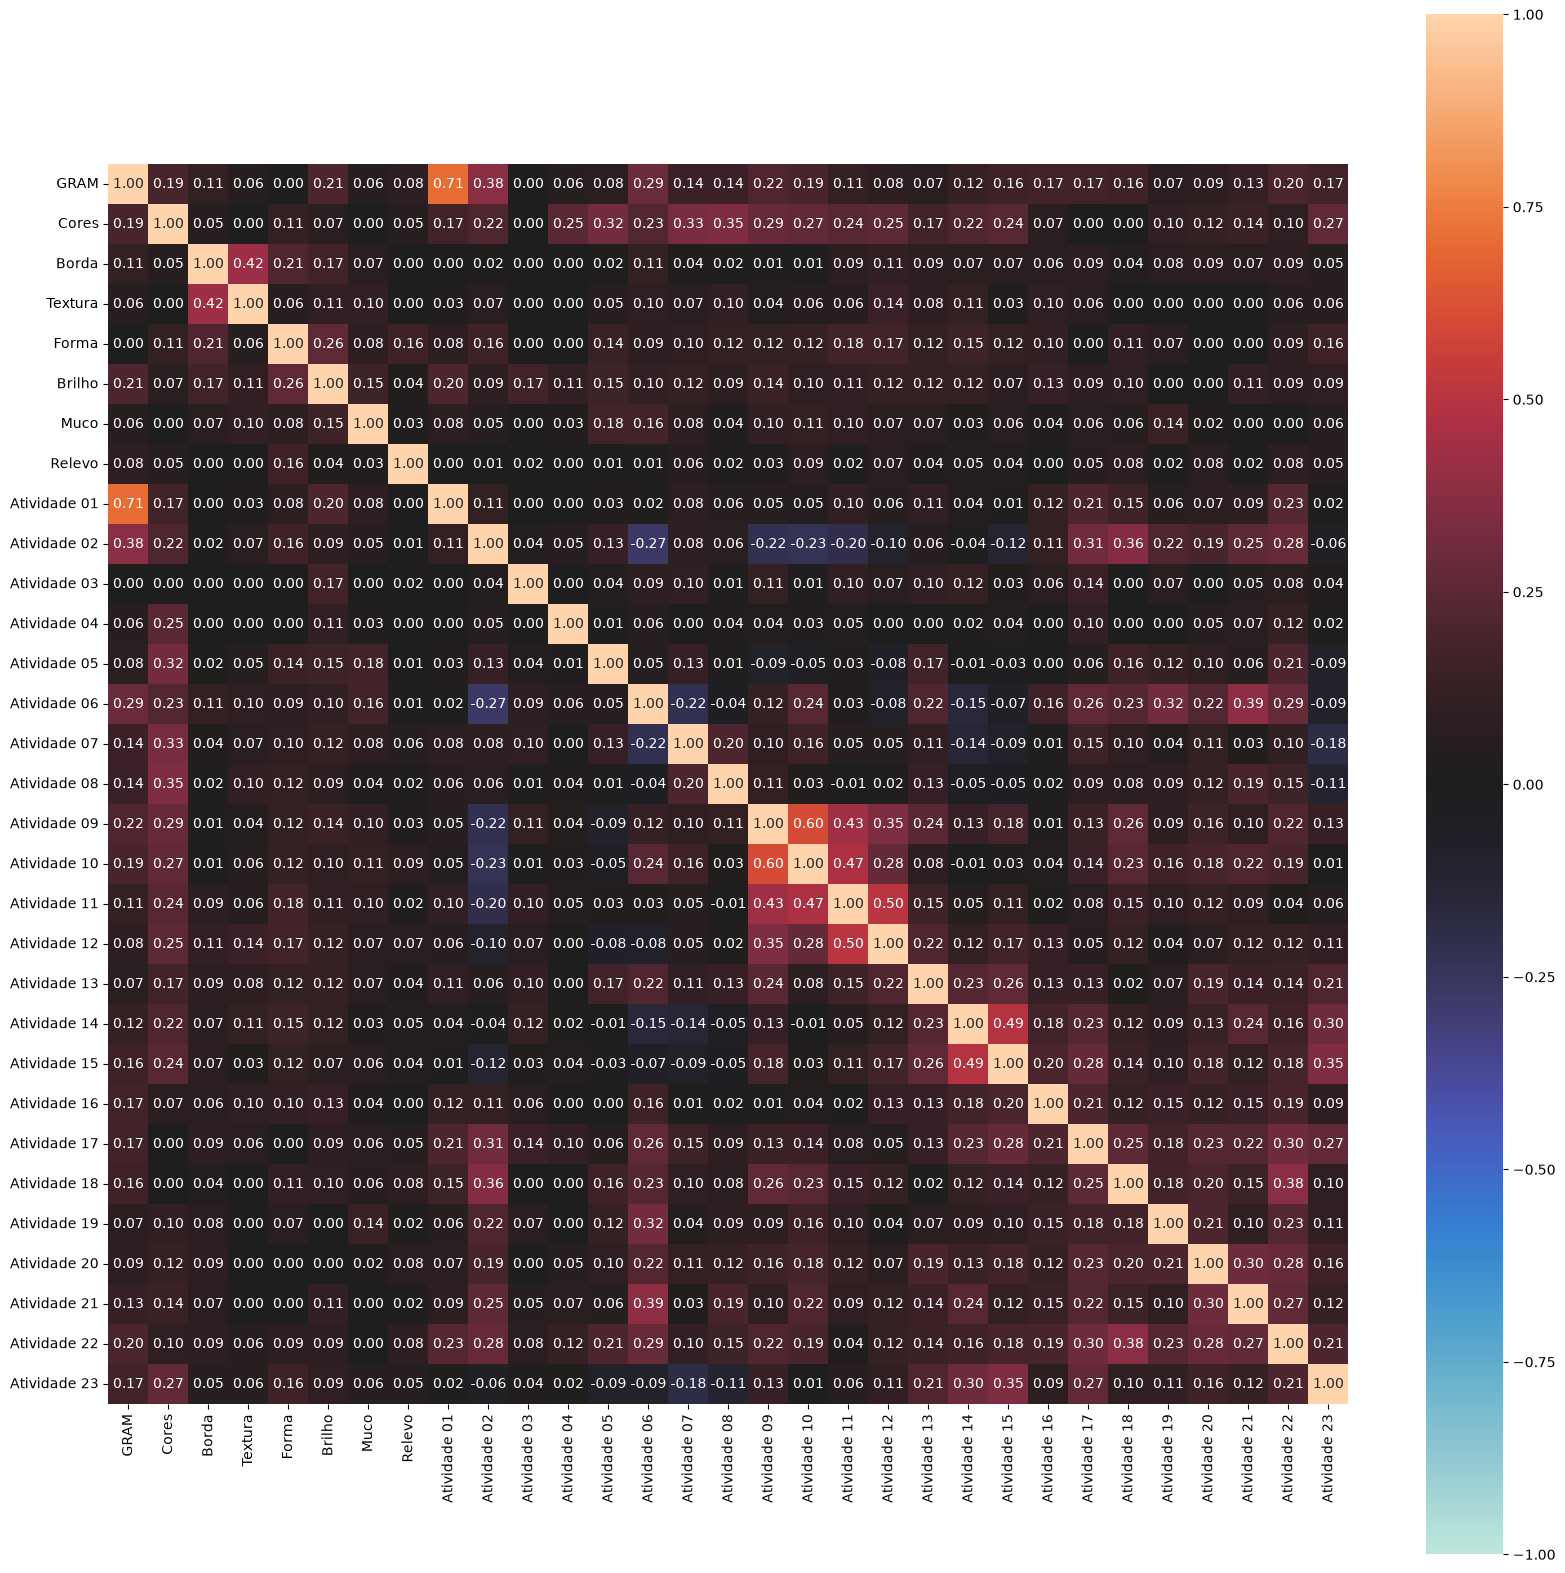

In [79]:
CAT_COLS = [                # col. categoricas
    "GRAM",
    "Cores",
    "Borda",
    "Textura",
    "Forma",
    "Brilho",
    "Muco",
    "Relevo",
    "Atividade 01",
    "Atividade 03",
    "Atividade 04",
    "Atividade 13",
    "Atividade 16",
    "Atividade 17",
    "Atividade 18",
    "Atividade 19",
    "Atividade 20",
    "Atividade 21",
    "Atividade 22",
]    
assoc = associations(
    df,
    nominal_columns=CAT_COLS,
    plot=True,
    figsize=(20, 20)
)

matriz = assoc['corr']

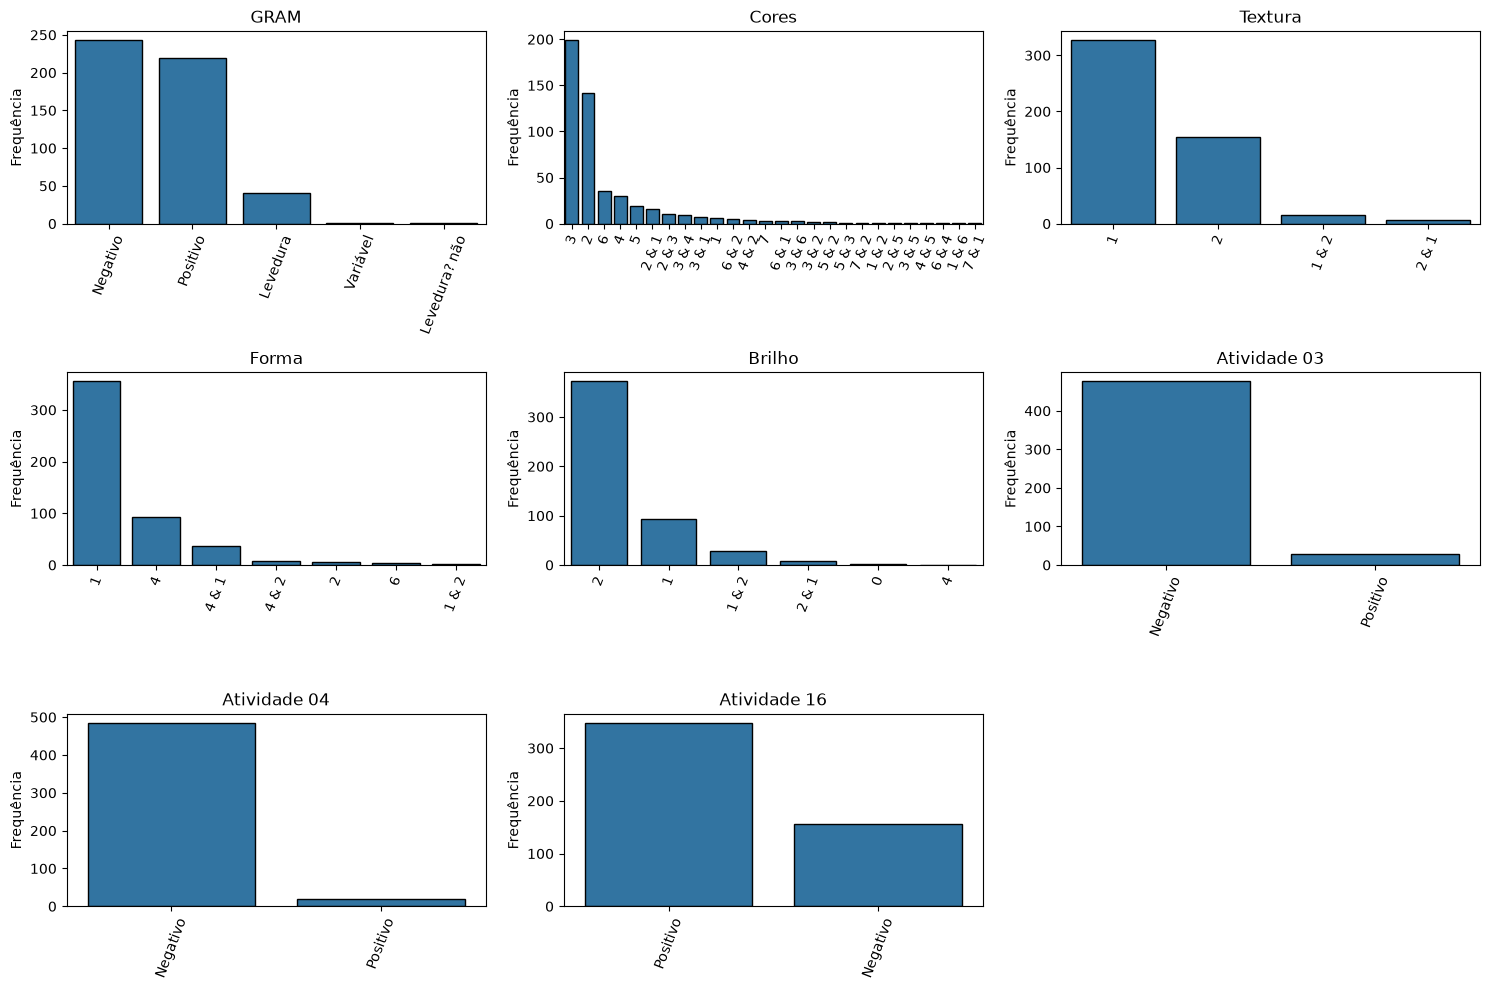

In [80]:
#VISUALIZANDO HISTOGRAMA DAS COLUNAS CATEGORICAS
cat = df.select_dtypes(exclude="number")

fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, col in zip(axes.flat, cat.columns):
    sns.countplot(
        data=df,
        x=col,
        ax=ax,
        edgecolor="black",
        order=df[col].value_counts().index,
    )

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Frequência")
    ax.tick_params(axis="x", rotation=69)

# Remove gráficos vazios
for ax in axes.flat[len(cat.columns):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

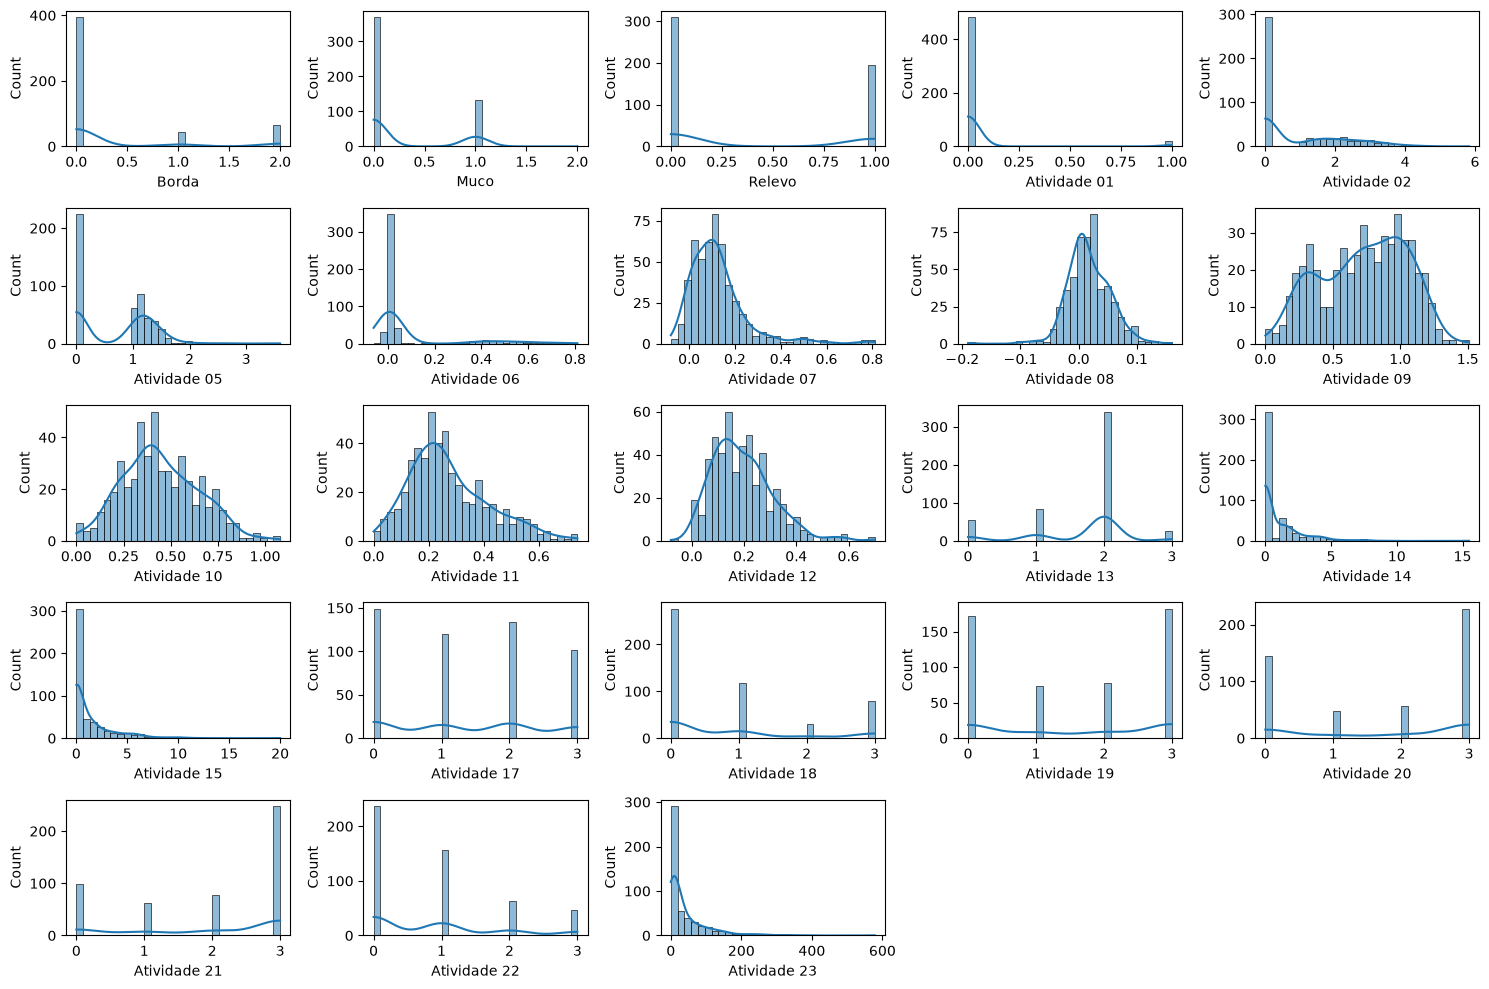

In [81]:
#VISUALIZANDO HISTOGRAMA DAS COLUNAS NUMERICAS JUNTO COM LINHA DE TENDENCIA
numeric_cols = df.select_dtypes(include="number").columns

ncols = 5
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(15, 2 * nrows)
)

axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        edgecolor="black",
        ax=ax
    )

# Remove os subplots vazios
for ax in axes[len(numeric_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

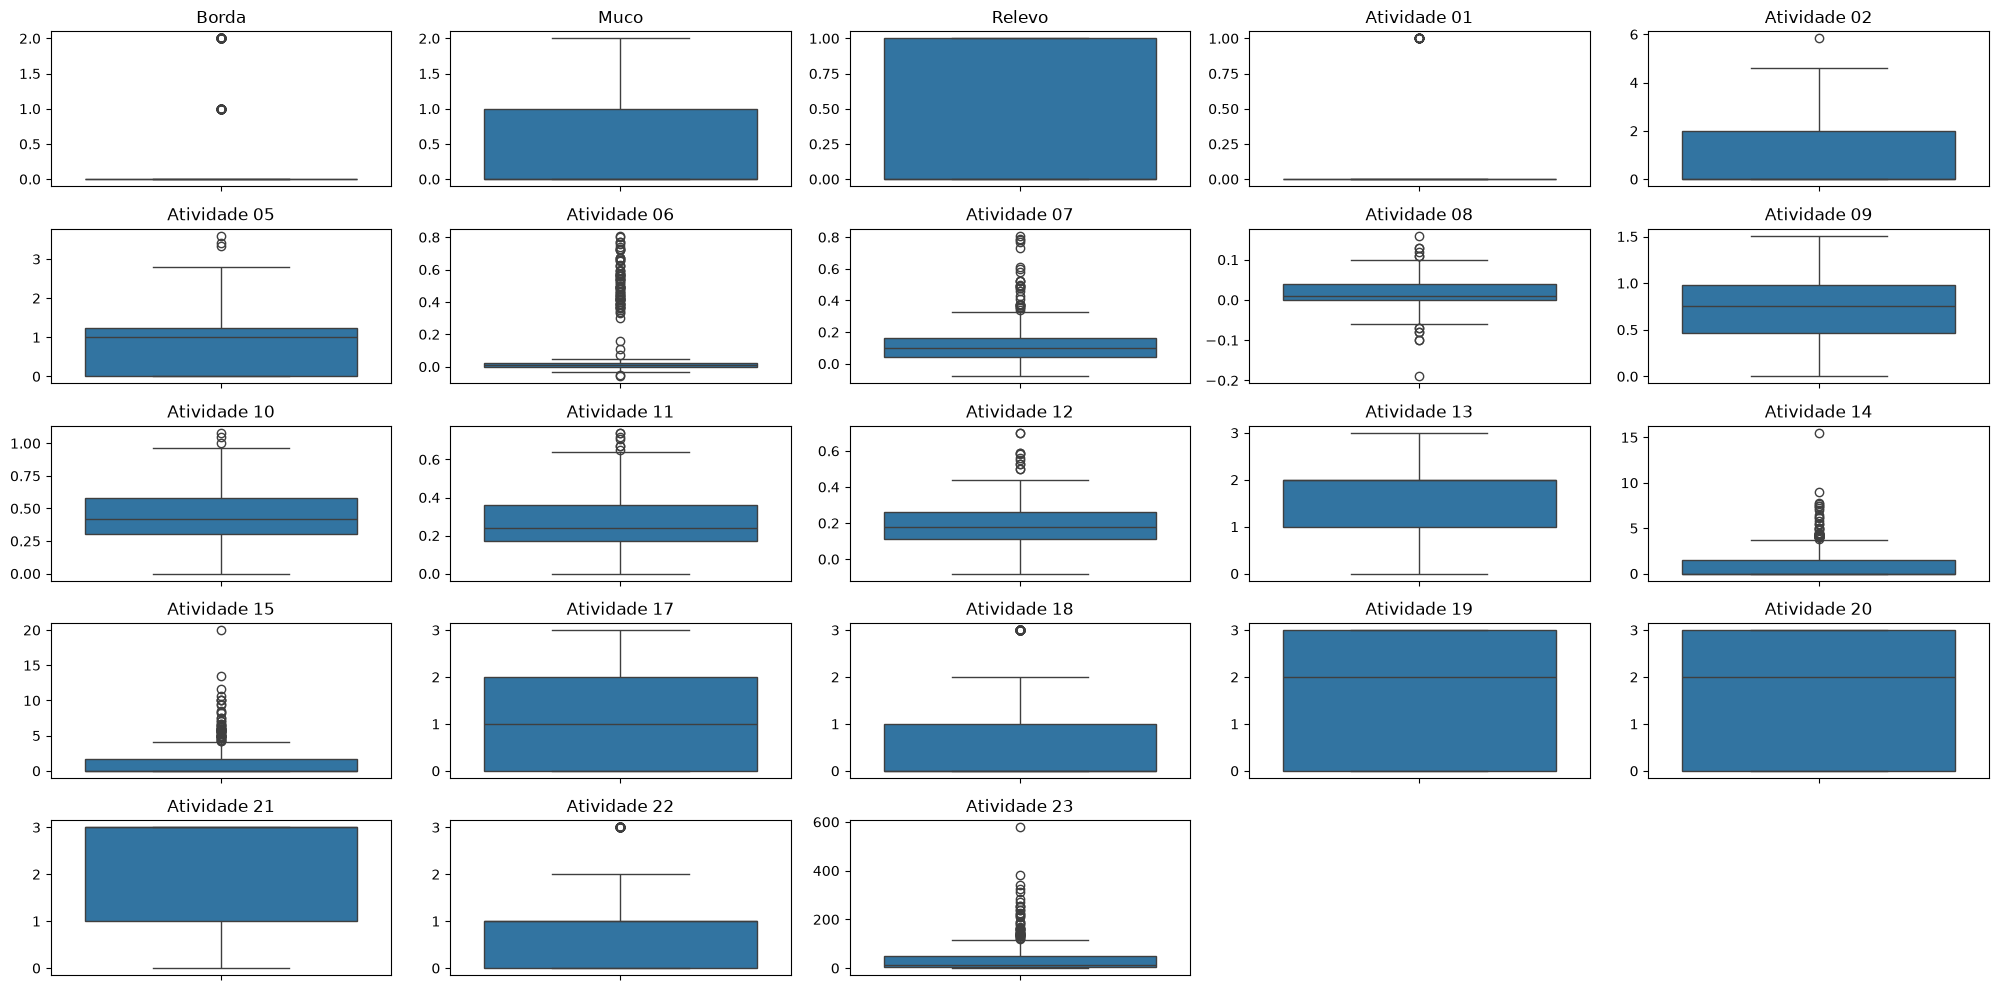

In [4]:
#VISUALIZANDO BOXPLOT DOS VALORES NUMERICOS
cols = df.select_dtypes("number").columns[:50]  

fig, axes = plt.subplots(5, 5, figsize=(20, 10))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()